In [1]:
import time, re, unicodedata, torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from transformers import AutoTokenizer, AutoModelForCausalLM
from ollama import Client
from ipywidgets import interact
from glob import glob

In [2]:
client = Client(host='http://localhost:11434')

In [3]:
client.list()

ListResponse(models=[Model(model='hf.co/HauhauCS/Qwen3.8-27B-Uncensored-HauhauCS-Aggressive-MTP-GGUF:IQ2_M', modified_at=datetime.datetime(2026, 9, 18, 17, 1, 14, 848591, tzinfo=TzInfo(10800)), digest='79829d246c574a2c535016cc3ae384487b75dad3fe75a9e6237939e41f74274f', size=11251054049, details=ModelDetails(parent_model='', format='gguf', family='qwen35', families=['qwen35'], parameter_size='1.86B', quantization_level='unknown')), Model(model='phi4-reasoning:latest', modified_at=datetime.datetime(2026, 9, 13, 13, 18, 49, 353572, tzinfo=TzInfo(10800)), digest='47e2630ccbcd361abcc9f90d8e8a5ada92583e4d5f9359192130372b42132315', size=11117503233, details=ModelDetails(parent_model='', format='gguf', family='phi3', families=['phi3'], parameter_size='14.7B', quantization_level='Q4_K_M')), Model(model='mistral:latest', modified_at=datetime.datetime(2026, 9, 13, 13, 16, 28, 319293, tzinfo=TzInfo(10800)), digest='6577803aa9a036369e481d648a2baebb381ebc6e897f2bb9a766a2aa7bfbc1cf', size=4372824384, 

In [4]:
for model in client.list().models:
    print(model.model)

hf.co/HauhauCS/Qwen3.8-27B-Uncensored-HauhauCS-Aggressive-MTP-GGUF:IQ2_M
phi4-reasoning:latest
mistral:latest
llama3.1:latest
qwen3.5:9b
gemma4:latest
llama3.2:latest
qwen3.8:latest
deepseek-v4.1-flash:cloud
gpt-oss:120b-cloud
qwen3.6:27b


In [5]:
MODELS = [model.model for model in client.list().models]

In [6]:
def get_model_name(model):
    return model.split(':')[0]

In [7]:
[get_model_name(model) for model in MODELS]

['hf.co/HauhauCS/Qwen3.8-27B-Uncensored-HauhauCS-Aggressive-MTP-GGUF',
 'phi4-reasoning',
 'mistral',
 'llama3.1',
 'qwen3.5',
 'gemma4',
 'llama3.2',
 'qwen3.8',
 'deepseek-v4.1-flash',
 'gpt-oss',
 'qwen3.6']

In [8]:
GEN_OPTIONS = {
    "temperature": 0.2,
    "top_p": 0.9,
    "repeat_penalty": 1.1
}

In [9]:
SYSTEM_PROMPT = """Ești un asistent educațional. Răspunde concis și exact
'RĂSPUNS FINAL: <răspuns>' (fără alte cuvinte).
Pentru probleme de matematică: arată pașii, apoi scrie pe o linie separată exact
'RĂSPUNS FINAL: <valoare>' (fără alte cuvinte)."""

In [10]:
DATASET = [
    # --- Istorie ---
    {
        "id": 1,
        "cat": "istorie",
        "q": "Cine a fost primul domnitor al Principatelor Unite ale Moldovei și Țării Românești?",
        "ref": "Alexandru Ioan Cuza"
    },
    {
        "id": 2,
        "cat": "istorie",
        "q": "În ce an a căzut Constantinopolul sub stăpânirea Imperiului Otoman?",
        "ref": "1453"
    },
    {
        "id": 3,
        "cat": "istorie",
        "q": "Cum s-a numit regele dac care a luptat împotriva împăratului roman Traian?",
        "ref": "Decebal"
    },
    {
        "id": 4,
        "cat": "istorie",
        "q": "În ce an a fost adoptată Declarația de Independență a Republicii Moldova?",
        "ref": "1991"
    },
    {
        "id": 5,
        "cat": "istorie",
        "q": "Cine a condus prima unire a celor trei principate românești în anul 1600?",
        "ref": "Mihai Viteazul"
    },
    {
        "id": 6,
        "cat": "istorie",
        "q": "În ce an s-a încheiat Al Doilea Război Mondial?",
        "ref": "1945"
    },

    # --- Limba română ---
    {
        "id": 7,
        "cat": "română",
        "q": "Care este pluralul corect al substantivului „monedă”?",
        "ref": "monede"
    },
    {
        "id": 8,
        "cat": "română",
        "q": "Care este antonimul cuvântului „generos”: „zgârcit” sau „darnic”?",
        "ref": "zgârcit"
    },
    {
        "id": 9,
        "cat": "română",
        "q": "Care este forma corectă: „crează” sau „creează”?",
        "ref": "creează"
    },
    {
        "id": 10,
        "cat": "română",
        "q": "Ce parte de vorbire este „repede” în propoziția „Calul aleargă repede”?",
        "ref": "adverb"
    },
    {
        "id": 11,
        "cat": "română",
        "q": "Indică sinonimul cuvântului „inteligent”: „isteț” sau „neatent”?",
        "ref": "isteț"
    },
    {
        "id": 12,
        "cat": "română",
        "q": "Care este forma corectă a verbului: „eu continui” sau „eu continuu”?",
        "ref": "eu continui"
    },

    # --- Matematică ---
    {
        "id": 13,
        "cat": "matematica",
        "q": "Calculează: 584 + 279 =",
        "ref": "863"
    },
    {
        "id": 14,
        "cat": "matematica",
        "q": "Calculează: 800 - 326 =",
        "ref": "474"
    },
    {
        "id": 15,
        "cat": "matematica",
        "q": "Calculează: 45 × 14 =",
        "ref": "630"
    },
    {
        "id": 16,
        "cat": "matematica",
        "q": "Calculează: 720 ÷ 9 =",
        "ref": "80"
    },
    {
        "id": 17,
        "cat": "matematica",
        "q": "Rezolvă pentru x: 4x + 7 = 31",
        "ref": "6"
    },
    {
        "id": 18,
        "cat": "matematica",
        "q": "Rezolvă pentru x: 5x - 8 = 17",
        "ref": "5"
    },
    {
        "id": 19,
        "cat": "matematica",
        "q": "Calculează: (18 - 6) × (20 ÷ 4) =",
        "ref": "60"
    },
    {
        "id": 20,
        "cat": "matematica",
        "q": "Calculează: 8² + 6² =",
        "ref": "100"
    }
]

In [10]:
DATASET = [
    # --- Istorie ---
    {
        "id": 1,
        "cat": "istorie",
        "q": "Cine a fost primul domnitor al Principatelor Unite ale Moldovei și Țării Românești?",
        "ref": "Alexandru Ioan Cuza"
    },
    {
        "id": 2,
        "cat": "istorie",
        "q": "În ce an a căzut Constantinopolul sub stăpânirea Imperiului Otoman?",
        "ref": "1453"
    },
    {
        "id": 3,
        "cat": "istorie",
        "q": "Cum s-a numit regele dac care a luptat împotriva împăratului roman Traian?",
        "ref": "Decebal"
    },
    {
        "id": 4,
        "cat": "istorie",
        "q": "În ce an a fost adoptată Declarația de Independență a Republicii Moldova?",
        "ref": "1991"
    },
    {
        "id": 5,
        "cat": "istorie",
        "q": "Cine a condus prima unire a celor trei principate românești în anul 1600?",
        "ref": "Mihai Viteazul"
    },
    {
        "id": 6,
        "cat": "istorie",
        "q": "În ce an s-a încheiat Al Doilea Război Mondial?",
        "ref": "1945"
    },

    # --- Limba română ---
    {
        "id": 7,
        "cat": "română",
        "q": "Care este pluralul corect al substantivului „monedă”?",
        "ref": "monede"
    },
    {
        "id": 8,
        "cat": "română",
        "q": "Care este antonimul cuvântului „generos”: „zgârcit” sau „darnic”?",
        "ref": "zgârcit"
    },
    {
        "id": 9,
        "cat": "română",
        "q": "Care este forma corectă: „crează” sau „creează”?",
        "ref": "creează"
    },
    {
        "id": 10,
        "cat": "română",
        "q": "Ce parte de vorbire este „repede” în propoziția „Calul aleargă repede”?",
        "ref": "adverb"
    },
    {
        "id": 11,
        "cat": "română",
        "q": "Indică sinonimul cuvântului „inteligent”: „isteț” sau „neatent”?",
        "ref": "isteț"
    },
    {
        "id": 12,
        "cat": "română",
        "q": "Care este forma corectă a verbului: „eu continui” sau „eu continuu”?",
        "ref": "eu continui"
    },

    # --- Matematică ---
    {
        "id": 13,
        "cat": "matematica",
        "q": "Calculează: 584 + 279 =",
        "ref": "863"
    },
    {
        "id": 14,
        "cat": "matematica",
        "q": "Calculează: 800 - 326 =",
        "ref": "474"
    },
    {
        "id": 15,
        "cat": "matematica",
        "q": "Calculează: 45 × 14 =",
        "ref": "630"
    },
    {
        "id": 16,
        "cat": "matematica",
        "q": "Calculează: 720 ÷ 9 =",
        "ref": "80"
    },
    {
        "id": 17,
        "cat": "matematica",
        "q": "Rezolvă pentru x: 4x + 7 = 31",
        "ref": "6"
    },
    {
        "id": 18,
        "cat": "matematica",
        "q": "Rezolvă pentru x: 5x - 8 = 17",
        "ref": "5"
    },
    {
        "id": 19,
        "cat": "matematica",
        "q": "Calculează: (18 - 6) × (20 ÷ 4) =",
        "ref": "60"
    },
    {
        "id": 20,
        "cat": "matematica",
        "q": "Calculează: 8² + 6² =",
        "ref": "100"
    }
]

In [30]:
for item in DATASET:
    if item['cat'] == 'matematica':
        item['ref_num'] = float(item['ref'])

In [11]:
FINAL_ANSWER_TEXT = 'raspuns final:'

def normalize_text(text, split):
    text = ''.join(
        c for c in unicodedata.normalize('NFD', text)
        if unicodedata.category(c) != 'Mn'
    ).lower()

    if split:
        possible_ans = text.rfind(FINAL_ANSWER_TEXT)
        if possible_ans != -1:
            text = text[possible_ans + len(FINAL_ANSWER_TEXT):]

    text = set(re.findall(r'\w+', text))
    return text

In [12]:
print(normalize_text('Mica Unire a avut loc în 1859.\nRĂSPUNS FINAL: 1859', True))

{'1859'}


In [13]:
def jaccard_tokens(a, b):
    if len(a) == 0 and len(b) == 0:
        return 1.0
    if len(a) == 0 or len(b) == 0:
        return 0.0
    return len(a & b) / len(a | b)

In [14]:
def factual_scores(model_answer, ref):
    a = normalize_text(model_answer, True)
    b = normalize_text(ref, False)
    partial = jaccard_tokens(a, b)
    return {
        'exact': int(partial > 0.9999),
        'partial': partial
    }

In [15]:
print(factual_scores('RĂSPUNS FINAL: Chișinău', 'Chișinău'))
# {'exact': 1, 'partial': 1.0}

{'exact': 1, 'partial': 1.0}


In [16]:
NUMBER_PATTERN = r'[+-]?\d+(?:[.,]\d+)?'
FINAL_MATH_ANS_RE = re.compile(
    fr'RĂSPUNS FINAL:\s*({NUMBER_PATTERN})',
    re.IGNORECASE
)

def parse_final_number(text):
    m = FINAL_MATH_ANS_RE.search(text)

    if m is None:
        candidates = re.findall(NUMBER_PATTERN, text)
        if not candidates:
            return np.nan
        val = candidates[-1]
    else:
        val = m.group(1)

    val = val.replace(',', '.')
    try:
        return float(val)
    except Exception:
        return np.nan

In [17]:
print(parse_final_number('Pași...\nRĂSPUNS FINAL: 623'))
# 623.0

print(parse_final_number('Rezultatul este 70'))
# 70.0

623.0
70.0


In [18]:
MATH_ANS_RE = re.compile(
    r'(^|\n)\s*(pas(ul)?|\d+[.)])',
    re.IGNORECASE
)

def math_score(model_answer, ref_num):
    steps = int(bool(MATH_ANS_RE.search(model_answer)))
    num = parse_final_number(model_answer)

    if np.isnan(num):
        correct = 0
    else:
        correct = int(abs(num - ref_num) <= 1e-6)

    return {'correct': correct, 'extracted': num, 'has_steps': steps}

In [19]:
print(math_score('Pas 1: 245+378\nRĂSPUNS FINAL: 623', 623))
# {'correct': 1, 'extracted': 623.0, 'has_steps': 1}

print(math_score('RĂSPUNS FINAL: 100', 623))
# {'correct': 0, 'extracted': 100.0, 'has_steps': 0}

{'correct': 1, 'extracted': 623.0, 'has_steps': 1}
{'correct': 0, 'extracted': 100.0, 'has_steps': 0}


In [20]:
REF_LM = 'gpt2'
tok = AutoTokenizer.from_pretrained(REF_LM)
lm = AutoModelForCausalLM.from_pretrained(REF_LM)
lm.eval()

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=2304, nx=768)
          (c_proj): Conv1D(nf=768, nx=768)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=3072, nx=768)
          (c_proj): Conv1D(nf=768, nx=3072)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
  )
  (lm_head): Linear(in_features=768, out_features=50257, bias=False)
)

In [21]:
def ref_perplexity(text):
    stride = 512

    enc = tok(text, return_tensors='pt')
    input_ids = enc['input_ids']
    max_length = lm.config.n_positions

    nlls = []

    for i in range(0, input_ids.size(1), stride):
        begin_loc = max(i + stride - max_length, 0)
        end_loc = min(i + stride, input_ids.size(1))

        trg_len = end_loc - i
        input_ids_slice = input_ids[:, begin_loc:end_loc]

        target_ids = input_ids_slice.clone()
        target_ids[:, :-trg_len] = -100

        with torch.no_grad():
            out = lm(input_ids_slice, labels=target_ids)
            neg_log_likelihood = out.loss * trg_len

        nlls.append(neg_log_likelihood)

    ppl = torch.exp(torch.stack(nlls).sum() / input_ids.size(1))
    return float(ppl)

In [22]:
print(ref_perplexity('RĂSPUNS FINAL: 1859'))

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


1228.7314453125


In [23]:
def perf_from_final_chunk(first_token_time, start_time, last_chunk):
    def to_ms(ns):
        return (ns or 0) / 1e6

    eval_ms = to_ms(last_chunk.eval_duration)
    gen_tokens = int(last_chunk.eval_count)

    return {
        'ttft_ms': max(0.0, (first_token_time - start_time) * 1000.0),
        'total_ms': to_ms(last_chunk.total_duration),
        'load_ms': to_ms(last_chunk.load_duration),
        'prompt_eval_ms': to_ms(last_chunk.prompt_eval_duration),
        'eval_ms': eval_ms,
        'prompt_tokens': int(last_chunk.prompt_eval_count),
        'gen_tokens': gen_tokens,
        'tps': gen_tokens / (eval_ms / 1000.0) if eval_ms else 0.0
    }

In [24]:
def ask_model(model, user_prompt, tune):
    start = time.time()
    content = []
    first_token_ts = None
    last_chunk = None

    options = {'num_ctx': 4096}

    if tune:
        options.update(GEN_OPTIONS)

    stream = client.chat(
        model=model,
        messages=[
            {'role': 'system', 'content': SYSTEM_PROMPT},
            {'role': 'user', 'content': user_prompt}
        ],
        stream=True,
        options=options
    )

    for chunk in stream:
        last_chunk = chunk
        piece = chunk.message.content or ''

        if len(piece) > 0 and first_token_ts is None:
            first_token_ts = time.time()

        content.append(piece)

    full = ''.join(content)

    if first_token_ts is None:
        first_token_ts = time.time()

    perf = perf_from_final_chunk(first_token_ts, start, last_chunk)
    return full, perf

In [31]:
full, perf = ask_model(MODELS[5], 'Capitala Republicii Moldova este?', False)
print(full)
print(perf)

RĂSPUNS FINAL: Chișinău
{'ttft_ms': 36060.755014419556, 'total_ms': 37368.983778, 'load_ms': 1.580481, 'prompt_eval_ms': 2823.399, 'eval_ms': 14418.434, 'prompt_tokens': 106, 'gen_tokens': 120, 'tps': 8.32267914809611}


In [32]:
import os
os.makedirs('benchmarks', exist_ok=True)

In [40]:
import os

def preflight_check():
    ok = True
    print('=== Preflight ===')

    os.makedirs('benchmarks', exist_ok=True)
    print('[ok] folder benchmarks/')

    missing = []
    for name in (
        'client', 'MODELS', 'DATASET', 'GEN_OPTIONS', 'SYSTEM_PROMPT',
        'ask_model', 'ref_perplexity', 'factual_scores', 'math_score',
        'get_model_name'
    ):
        if name not in globals():
            missing.append(name)
    if missing:
        print('[fail] lipsesc:', missing)
        ok = False
    else:
        print('[ok] funcții și variabile definite')

    math_items = [x for x in DATASET if x.get('cat') == 'matematica']
    no_ref_num = [x['id'] for x in math_items if 'ref_num' not in x]
    if no_ref_num:
        print('[fail] itemi matematică fără ref_num:', no_ref_num)
        ok = False
    else:
        print(f'[ok] DATASET: {len(DATASET)} itemi, {len(math_items)} matematică cu ref_num')

    try:
        tags = client.list()
        names = [m.model if hasattr(m, 'model') else m.get('model') or m.get('name') for m in tags.models]
        print('[ok] Ollama conectat. Modele locale:', names)
        not_pulled = [m for m in MODELS if m not in names and not any(n.startswith(m) for n in names)]
        if not_pulled:
            print('[warn] nu sunt pe mașină (ollama pull):', not_pulled)
        else:
            print('[ok] toate MODELS sunt disponibile')
    except Exception as e:
        print('[fail] Ollama / client:', type(e).__name__, e)
        ok = False

    try:
        ppl = ref_perplexity('test')
        print(f'[ok] GPT-2 perplexity merge (ppl={ppl:.2f})')
    except Exception as e:
        print('[fail] ref_perplexity:', type(e).__name__, e)
        ok = False

    print('===', 'GATA DE BENCHMARK' if ok else 'REPARĂ ERORILE DE MAI SUS', '===')
    return ok

preflight_check()

=== Preflight ===
[ok] folder benchmarks/
[ok] funcții și variabile definite
[ok] DATASET: 20 itemi, 8 matematică cu ref_num
[ok] Ollama conectat. Modele locale: ['hf.co/HauhauCS/Qwen3.8-27B-Uncensored-HauhauCS-Aggressive-MTP-GGUF:IQ2_M', 'phi4-reasoning:latest', 'mistral:latest', 'llama3.1:latest', 'qwen3.5:9b', 'gemma4:latest', 'llama3.2:latest', 'qwen3.8:latest', 'deepseek-v4.1-flash:cloud', 'gpt-oss:120b-cloud', 'qwen3.6:27b']
[ok] toate MODELS sunt disponibile
[ok] GPT-2 perplexity merge (ppl=nan)
=== GATA DE BENCHMARK ===


True

In [51]:
def run_benchmark(model):
    if model is None:
        print('Selectează un model din dropdown.')
        return

    print(f'\n>>> START benchmark: {model}')
    print(f'    20 întrebări × 2 (tuned False/True) = 40 apeluri\n')
    rows = []
    n = 0
    total = len(DATASET) * 2

    for item in DATASET:
        for tuned in (False, True):
            n += 1
            tag = 'tuned' if tuned else 'default'
            print(f'[{n:02d}/{total}] id={item["id"]} cat={item["cat"]} {tag} ...', flush=True)

            try:
                full, perf = ask_model(model, item['q'], tuned)
                ppl = ref_perplexity(full)
            except Exception as e:
                print(f'    ERROARE: {type(e).__name__}: {e}')
                raise

            preview = (full or '').replace('\n', ' ')[:80]
            print(f'    ttft={perf["ttft_ms"]:.0f}ms tps={perf["tps"]:.1f} ppl={ppl:.1f} | {preview}')

            row = {
                'model': model,
                'tuned': tuned,
                'id': item['id'],
                'cat': item['cat'],
                'q': item['q'],
                'ref': item['ref'],
                'answer': full,
                'exact': np.nan,
                'partial': np.nan,
                'math_correct': np.nan,
                'has_steps': np.nan,
                'ttft_ms': perf['ttft_ms'],
                'tps': perf['tps'],
                'gen_tokens': perf['gen_tokens'],
                'total_ms': perf['total_ms'],
                'eval_ms': perf['eval_ms'],
                'prompt_eval_ms': perf['prompt_eval_ms'],
                'load_ms': perf['load_ms'],
                'ref_ppl': ppl,
            }

            if item['cat'] == 'matematica':
                ms = math_score(full, item['ref_num'])
                row['math_correct'] = ms['correct']
                row['has_steps'] = ms['has_steps']
                print(f'    math correct={ms["correct"]} extracted={ms["extracted"]} steps={ms["has_steps"]}')
            else:
                sc = factual_scores(full, item['ref'])
                row['exact'] = sc['exact']
                row['partial'] = sc['partial']
                print(f'    exact={sc["exact"]} partial={sc["partial"]:.3f}')

            rows.append(row)

    out = f'benchmarks/{get_model_name(model)}.json'
    pd.DataFrame(rows).to_json(out, orient='records', lines=True)
    print(f'\n>>> GATA. Salvat {len(rows)} rânduri în {out}')

In [50]:
from IPython.display import display, clear_output

model_dd = widgets.Dropdown(
    options=list(MODELS),
    description='Model:'
)
start_btn = widgets.Button(description='Start benchmark', button_style='success')
out = widgets.Output

def on_start(_):
    with out:
        clear_output(wait=True)
        print('start running')
        run_benchmark(model_dd.value)
        
start_btn.on_click(on_start)
display(model_dd, start_btn, out)

Dropdown(description='Model:', options=('hf.co/HauhauCS/Qwen3.8-27B-Uncensored-HauhauCS-Aggressive-MTP-GGUF:IQ…

Button(button_style='success', description='Start benchmark', style=ButtonStyle())

ipywidgets.widgets.widget_output.Output

In [53]:
run_benchmark('gemma4:latest')


>>> START benchmark: gemma4:latest
    20 întrebări × 2 (tuned False/True) = 40 apeluri

[01/40] id=1 cat=istorie default ...
    ttft=256047ms tps=7.9 ppl=394.2 | RĂSPUNS FINAL: Nu există un singur domnitor unic și definit în istorie. Unirea P
    exact=0 partial=0.000
[02/40] id=1 cat=istorie tuned ...
    ttft=58149ms tps=8.1 ppl=1381.5 | RĂSPUNS FINAL: Alexandru Ioan Cuza
    exact=1 partial=1.000
[03/40] id=2 cat=istorie default ...
    ttft=51933ms tps=9.1 ppl=1169.9 | RĂSPUNS FINAL: 1453
    exact=1 partial=1.000
[04/40] id=2 cat=istorie tuned ...
    ttft=37277ms tps=8.3 ppl=1169.9 | RĂSPUNS FINAL: 1453
    exact=1 partial=1.000
[05/40] id=3 cat=istorie default ...
    ttft=40178ms tps=8.4 ppl=1078.8 | RĂSPUNS FINAL: Decebalus
    exact=0 partial=0.000
[06/40] id=3 cat=istorie tuned ...
    ttft=48226ms tps=8.2 ppl=918.6 | RĂSPUNS FINAL: Decebal
    exact=1 partial=1.000
[07/40] id=4 cat=istorie default ...
    ttft=44127ms tps=8.4 ppl=1789.6 | RĂSPUNS FINAL: 1991
    exact=1 

In [ ]:
run_benchmark('qwen3.5:9b')


>>> START benchmark: qwen3.5:9b
    20 întrebări × 2 (tuned False/True) = 40 apeluri

[01/40] id=1 cat=istorie default ...
    ttft=878000ms tps=2.6 ppl=1381.5 | RĂSPUNS FINAL: Alexandru Ioan Cuza
    exact=1 partial=1.000
[02/40] id=1 cat=istorie tuned ...
    ttft=390207ms tps=2.6 ppl=1381.5 | RĂSPUNS FINAL: Alexandru Ioan Cuza
    exact=1 partial=1.000
[03/40] id=2 cat=istorie default ...
    ttft=498499ms tps=2.6 ppl=1169.9 | RĂSPUNS FINAL: 1453
    exact=1 partial=1.000
[04/40] id=2 cat=istorie tuned ...
    ttft=490606ms tps=2.6 ppl=1169.9 | RĂSPUNS FINAL: 1453
    exact=1 partial=1.000
[05/40] id=3 cat=istorie default ...
    ttft=1160910ms tps=2.5 ppl=918.6 | RĂSPUNS FINAL: Decebal
    exact=1 partial=1.000
[06/40] id=3 cat=istorie tuned ...


---

# Processarea rezultatelor

In [54]:
results_df = None

for file in glob('benchmarks/*.json'):
    temp = pd.read_json(file, lines=True)

    if results_df is None:
        results_df = temp
        continue

    results_df = pd.concat([results_df, temp], ignore_index=True)

results_df

,model,tuned,id,cat,q,ref,answer,exact,partial,math_correct,has_steps,ttft_ms,tps,gen_tokens,total_ms,eval_ms,prompt_eval_ms,load_ms,ref_ppl
0,gemma4:latest,False,1,istorie,Cine a fost primul domnitor al Principatelor U...,Alexandru Ioan Cuza,RĂSPUNS FINAL: Nu există un singur domnitor un...,0.0,0.000000,NaN,NaN,256046.700478,7.857120,1879,264596.006558,239146.152000,3228.373,1.348315,394.213043
1,gemma4:latest,True,1,istorie,Cine a fost primul domnitor al Principatelor U...,Alexandru Ioan Cuza,RĂSPUNS FINAL: Alexandru Ioan Cuza,1.0,1.000000,NaN,NaN,58148.672342,8.068711,467,59795.398501,57877.897000,294.899,1.450812,1381.529541
2,gemma4:latest,False,2,istorie,În ce an a căzut Constantinopolul sub stăpânir...,1453,RĂSPUNS FINAL: 1453,1.0,1.000000,NaN,NaN,51933.027506,9.121668,13,53357.077154,1425.178000,286.235,1.479660,1169.933350
3,gemma4:latest,True,2,istorie,În ce an a căzut Constantinopolul sub stăpânir...,1453,RĂSPUNS FINAL: 1453,1.0,1.000000,NaN,NaN,37276.514769,8.302802,152,38757.762217,18307.073000,290.344,1.609283,1169.933350
4,gemma4:latest,False,3,istorie,Cum s-a numit regele dac care a luptat împotri...,Decebal,RĂSPUNS FINAL: Decebalus,0.0,0.000000,NaN,NaN,40178.246498,8.381942,195,41517.223089,23264.299000,286.731,1.658737,1078.834351
5,gemma4:latest,True,3,istorie,Cum s-a numit regele dac care a luptat împotri...,Decebal,RĂSPUNS FINAL: Decebal,1.0,1.000000,NaN,NaN,48225.938559,8.248345,192,49466.525761,23277.398000,288.343,1.752930,918.642883
6,gemma4:latest,False,4,istorie,În ce an a fost adoptată Declarația de Indepen...,1991,RĂSPUNS FINAL: 1991,1.0,1.000000,NaN,NaN,44126.685619,8.412801,192,45571.852026,22822.362000,284.352,1.877354,1789.587402
7,gemma4:latest,True,4,istorie,În ce an a fost adoptată Declarația de Indepen...,1991,RĂSPUNS FINAL: 1991,1.0,1.000000,NaN,NaN,58530.004263,8.154486,261,60016.487028,32006.921000,325.609,1.475625,1789.587402
8,gemma4:latest,False,5,istorie,Cine a condus prima unire a celor trei princip...,Mihai Viteazul,RĂSPUNS FINAL: Nu există un nume singur. În an...,0.0,0.000000,NaN,NaN,137959.039450,8.051336,1004,150054.453498,124699.794000,3205.230,2.417665,367.369354
9,gemma4:latest,True,5,istorie,Cine a condus prima unire a celor trei princip...,Mihai Viteazul,RĂSPUNS FINAL: Nu există un lider istoric recu...,0.0,0.000000,NaN,NaN,236049.477577,7.935744,957,241122.800682,120593.605000,306.910,1.958616,629.666870


In [55]:
agg = results_df.groupby(['model', 'tuned']).agg(
    factual_exact=('exact', 'mean'),
    factual_partial=('partial', 'mean'),
    math_acc=('math_correct', 'mean'),
    steps_rate=('has_steps', 'mean'),
    ttft_ms=('ttft_ms', 'mean'),
    tps=('tps', 'mean'),
    ref_ppl=('ref_ppl', 'mean'),
    gen_tokens=('gen_tokens', 'mean'),
).reset_index()

agg

,model,tuned,factual_exact,factual_partial,math_acc,steps_rate,ttft_ms,tps,ref_ppl,gen_tokens
0,gemma4:latest,False,0.666667,0.666667,1.0,0.50,67902.340162,8.438487,889.209653,331.65
1,gemma4:latest,True,0.750000,0.777778,1.0,0.75,58492.948568,8.130843,933.634899,310.05


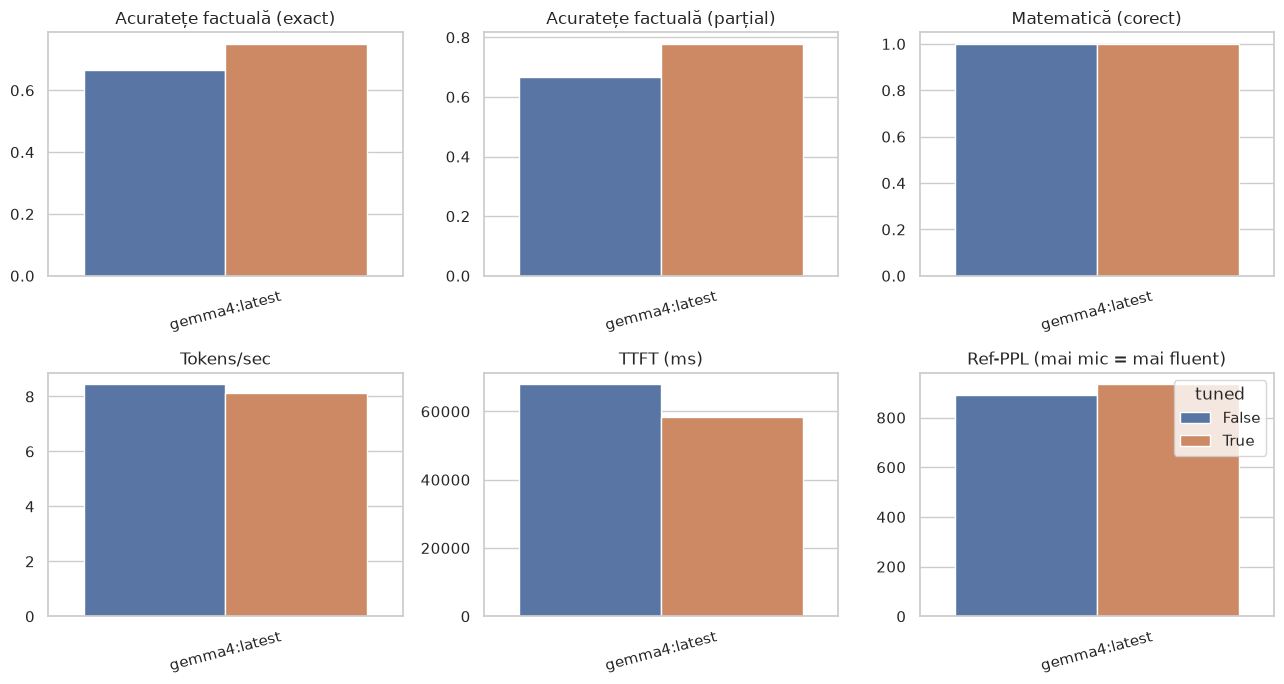

In [56]:
sns.set_theme(style='whitegrid')

fig, axes = plt.subplots(2, 3, figsize=(13, 7))

sns.barplot(data=agg, x='model', y='factual_exact', hue='tuned', legend=False, ax=axes[0, 0])
axes[0, 0].set_title('Acuratețe factuală (exact)')

sns.barplot(data=agg, x='model', y='factual_partial', hue='tuned', legend=False, ax=axes[0, 1])
axes[0, 1].set_title('Acuratețe factuală (parțial)')

sns.barplot(data=agg, x='model', y='math_acc', hue='tuned', legend=False, ax=axes[0, 2])
axes[0, 2].set_title('Matematică (corect)')

sns.barplot(data=agg, x='model', y='tps', hue='tuned', legend=False, ax=axes[1, 0])
axes[1, 0].set_title('Tokens/sec')

sns.barplot(data=agg, x='model', y='ttft_ms', hue='tuned', legend=False, ax=axes[1, 1])
axes[1, 1].set_title('TTFT (ms)')

sns.barplot(data=agg, x='model', y='ref_ppl', hue='tuned', ax=axes[1, 2])
axes[1, 2].set_title('Ref-PPL (mai mic = mai fluent)')

for ax in axes.ravel():
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.show()

In [57]:
def save_json(df, name):
    df.to_json(name, orient='records', indent=4)

save_json(results_df, 'ollama_eval_item_level.json')
save_json(agg, 'ollama_eval_aggregate.json')